# Identifying Statistical Significance of Arrest Clustering in Los Angeles

### As part of our project examining the extraction of Million Dollar Hoods, we are looking at data around arrests in LA County and determining whether arrest clusters are happening in our key sites.
#### Project by Hollis Potts, Amil Hogan, and Leila Ullmann

In [1]:
# read in the libraries
# to read and wrangle data
import pandas as pd

# to import data from LA Data portal
from sodapy import Socrata

# to create spatial data
import geopandas as gpd

# for basemaps
import contextily as ctx

# For spatial statistics
import esda
from esda.moran import Moran, Moran_Local

import splot
from splot.esda import moran_scatterplot, plot_moran, lisa_cluster,plot_moran_simulation

import libpysal as lps

# Graphics
import matplotlib.pyplot as plt
import plotly.express as px

### Read in the Data

In [3]:
# to illustrate, bring in tracts
gdf_tracts = gpd.read_file('tracts.geojson')

In [5]:
# population block group data from census reporter
# gdf_bg = gpd.read_file('data/acs2019_5yr_B01003_15000US060372672002.geojson')
gdf_bg = gpd.read_file('acs2021_5yr_B01003_15000US060371041082.geojson')

### Clean the Data

In [6]:
# what does our data look like?
gdf_bg.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 2685 entries, 0 to 2684
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   geoid             2685 non-null   object  
 1   name              2685 non-null   object  
 2   B01003001         2685 non-null   float64 
 3   B01003001, Error  2685 non-null   float64 
 4   geometry          2685 non-null   geometry
dtypes: float64(2), geometry(1), object(2)
memory usage: 105.0+ KB


In [7]:
# trim the data to the bare minimum columns
gdf_bg = gdf_bg[['geoid','B01003001','geometry']]

# rename the columns
gdf_bg.columns = ['FIPS','TotalPop','geometry']

In [8]:
# last rows
gdf_bg.tail()

,FIPS,TotalPop,geometry
2680,15000US060379800281,0.0,"MULTIPOLYGON (((-118.45246 33.94315, -118.4464..."
2681,15000US060379800311,1160.0,"MULTIPOLYGON (((-118.29105 33.75378, -118.2905..."
2682,15000US060379800391,0.0,"MULTIPOLYGON (((-118.36215 34.13903, -118.3612..."
2683,15000US060379902000,0.0,"MULTIPOLYGON (((-118.63598 34.03255, -118.6325..."
2684,16000US0644000,3902440.0,"MULTIPOLYGON (((-118.66818 34.18987, -118.6681..."


In [9]:
# delete last row which is for the entire city of LA
gdf_bg.drop(gdf_bg.tail(1).index,inplace=True)

In [10]:
# fix FIPS code
gdf_bg['FIPS'] = gdf_bg['FIPS'].str.replace('15000US','')
gdf_bg.tail()

,FIPS,TotalPop,geometry
2679,060379800261,16.0,"MULTIPOLYGON (((-118.35173 34.28034, -118.3517..."
2680,060379800281,0.0,"MULTIPOLYGON (((-118.45246 33.94315, -118.4464..."
2681,060379800311,1160.0,"MULTIPOLYGON (((-118.29105 33.75378, -118.2905..."
2682,060379800391,0.0,"MULTIPOLYGON (((-118.36215 34.13903, -118.3612..."
2683,060379902000,0.0,"MULTIPOLYGON (((-118.63598 34.03255, -118.6325..."


In [11]:
# sort by total pop
gdf_bg.sort_values(by='TotalPop').head(20)

,FIPS,TotalPop,geometry
2683,060379902000,0.0,"MULTIPOLYGON (((-118.63598 34.03255, -118.6325..."
2682,060379800391,0.0,"MULTIPOLYGON (((-118.36215 34.13903, -118.3612..."
2676,060379800221,0.0,"MULTIPOLYGON (((-118.50266 34.30809, -118.5026..."
2674,060379800201,0.0,"MULTIPOLYGON (((-118.34414 34.21615, -118.3441..."
2247,060372653012,0.0,"MULTIPOLYGON (((-118.44878 34.06862, -118.4486..."
2680,060379800281,0.0,"MULTIPOLYGON (((-118.45246 33.94315, -118.4464..."
2677,060379800231,0.0,"MULTIPOLYGON (((-118.6487 34.2312, -118.64803 ..."
2668,060379800091,5.0,"MULTIPOLYGON (((-118.33707 34.1416, -118.33616..."
2679,060379800261,16.0,"MULTIPOLYGON (((-118.35173 34.28034, -118.3517..."
2670,060379800141,44.0,"MULTIPOLYGON (((-118.26088 33.7685, -118.26029..."


In [12]:
# delete less than 100 population geographies
gdf_bg = gdf_bg[gdf_bg['TotalPop']>100]

### Map the census block groups

In [13]:
# get the layers into a web mercator projection
# reproject to web mercator
gdf_bg = gdf_bg.to_crs(epsg=3857)

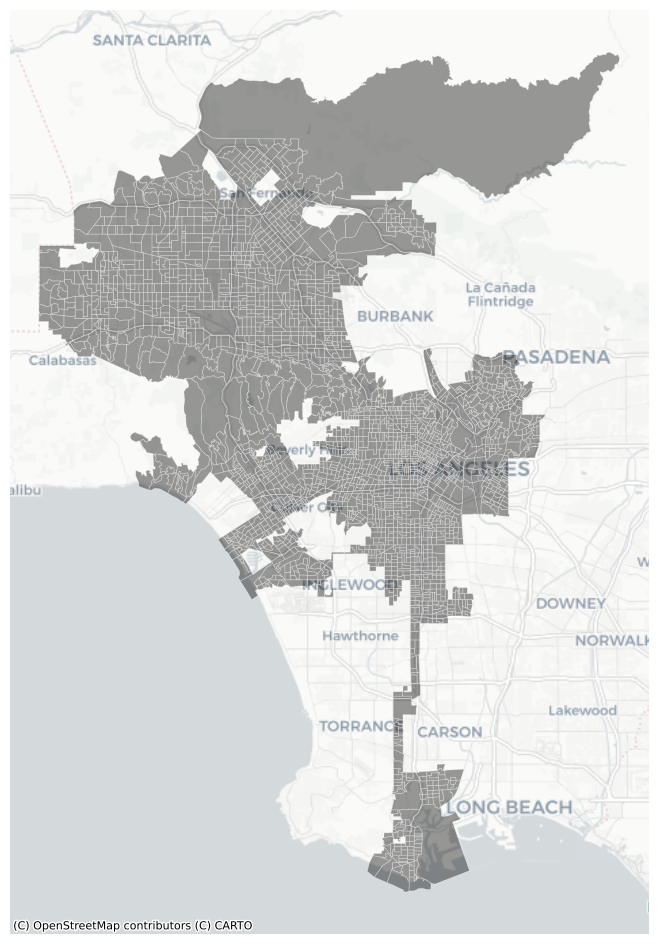

In [14]:
# plot it!
fig, ax = plt.subplots(figsize=(12,12))

gdf_bg.plot(ax=ax,
         color='black', 
         edgecolor='white',
         lw=0.5,
         alpha=0.4)

# no axis
ax.axis('off')

# add a basemap
ctx.add_basemap(ax,source=ctx.providers.CartoDB.Positron)

### Get Arrest Data from LA Open Data Portal

In [17]:
# connect to the data portal
client = Socrata("data.lacity.org", None)

results = client.get("amvf-fr72", 
                     limit=50000,
                     where = "arst_date between '2023-1-01T00:00:00' and '2023-4-01T00:00:00'",
                     order='arst_date desc')

# Convert to pandas DataFrame
arrests = pd.DataFrame.from_records(results)

In [18]:
arrests.shape

(14277, 25)

In [19]:
arrests.head()

,rpt_id,report_type,arst_date,time,area,area_desc,rd,age,sex_cd,descent_cd,...,dispo_desc,location,crsst,lat,lon,location_1,bkg_date,bkg_time,bkg_location,bkg_loc_cd
0,6578761,BOOKING,2023-04-01T00:00:00.000,1500,09,Van Nuys,0901,22,F,W,...,MISDEMEANOR COMPLAINT FILED,SEPULVEDA BL,VALERIO ST,34.2048,-118.4662,"{'type': 'Point', 'coordinates': [-118.4662, 3...",2023-04-01T00:00:00.000,1733,VALLEY - JAIL DIV,4279
1,6578829,BOOKING,2023-04-01T00:00:00.000,1620,13,Newton,1346,39,M,B,...,DISTRICT ATTORNEY REJECT,41 PL,DORSEY,34.006,-118.2513,"{'type': 'Point', 'coordinates': [-118.2513, 3...",2023-04-01T00:00:00.000,2122,METRO - JAIL DIVISION,4273
2,231007532,RFC,2023-04-01T00:00:00.000,2300,10,West Valley,1018,22,M,H,...,MISDEMEANOR COMPLAINT FILED,STRATHERN ST,HASKELL AV,34.2157,-118.4749,"{'type': 'Point', 'coordinates': [-118.4749, 3...",NaN,NaN,NaN,NaN
3,6578902,BOOKING,2023-04-01T00:00:00.000,2345,03,Southwest,0363,30,M,H,...,CITY ATTORNEY REJECT,4100 LOCKLAND PL,NaN,34.0093,-118.3405,"{'type': 'Point', 'coordinates': [-118.3405, 3...",2023-04-02T00:00:00.000,0120,77TH ST,4212
4,6578895,BOOKING,2023-04-01T00:00:00.000,2230,12,77th Street,1213,27,M,B,...,FELONY COMPLAINT FILED,5500 DENKER AV,NaN,33.9921,-118.3108,"{'type': 'Point', 'coordinates': [-118.3108, 3...",2023-04-02T00:00:00.000,0104,77TH ST,4212


### Convert data to a geodataframe

In [20]:
# convert pandas dataframe to geodataframe
arrests = gpd.GeoDataFrame(arrests, 
                         crs='EPSG:4326',
                         geometry=gpd.points_from_xy(arrests.lon, arrests.lat))

In [21]:
# get the layers into a web mercator projection
# reproject to web mercator
arrests = arrests.to_crs(epsg=3857)

In [22]:
# convert lat/lon to floats
arrests.lon = arrests.lon.astype('float')
arrests.lat = arrests.lat.astype('float')

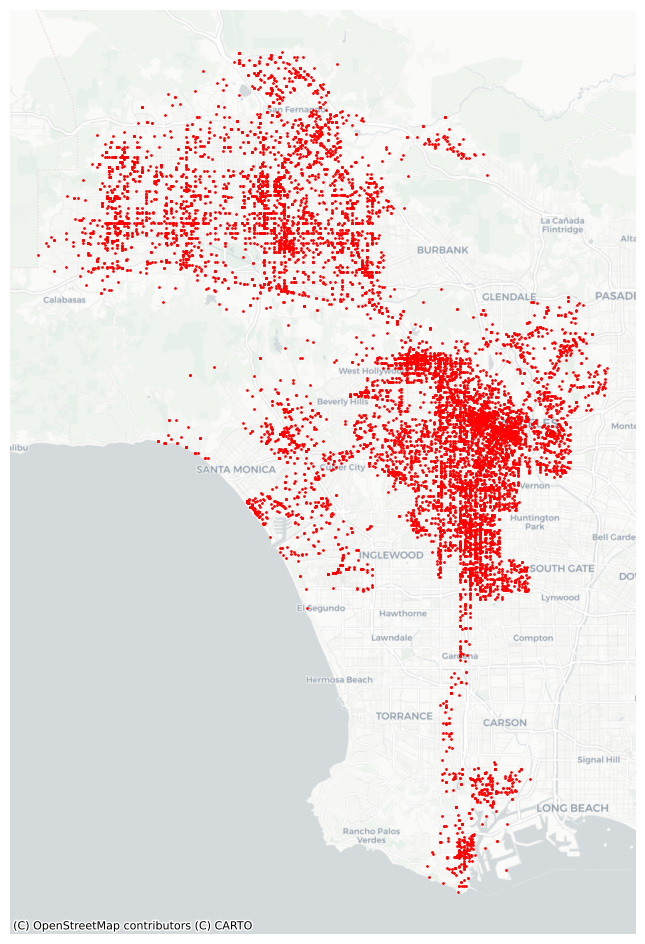

In [23]:
# map it!
fig,ax = plt.subplots(figsize=(12,12))

arrests.plot(ax=ax,
             color='red',
             markersize=1)

# no axis
ax.axis('off')

# add a basemap
ctx.add_basemap(ax,source=ctx.providers.CartoDB.Positron)

In [24]:
# subset the zero coordinate records
arrests[arrests.lon==0]

,rpt_id,report_type,arst_date,time,area,area_desc,rd,age,sex_cd,descent_cd,...,location,crsst,lat,lon,location_1,bkg_date,bkg_time,bkg_location,bkg_loc_cd,geometry


In [25]:
# drop the unmapped rows
arrests = arrests[arrests.lon!=0]

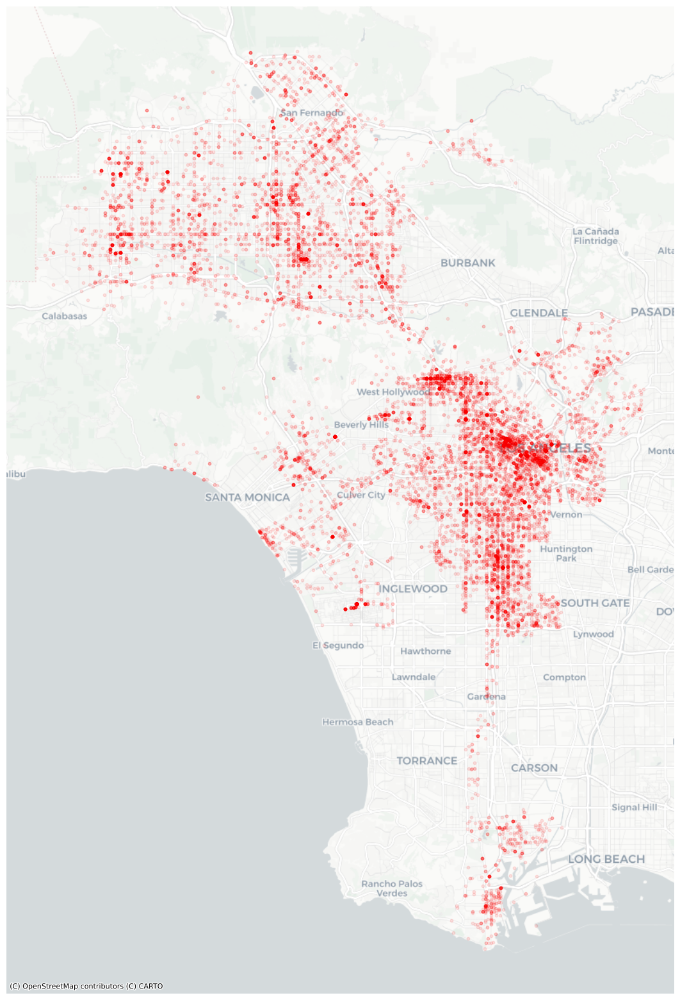

In [26]:
# map it!
fig,ax = plt.subplots(figsize=(20,20))

arrests.plot(ax=ax,
             color='red',
             markersize=10, alpha=0.1)

# no axis
ax.axis('off')

# add a basemap
ctx.add_basemap(ax,source=ctx.providers.CartoDB.Positron)


### Create a two layer map

In [27]:
# get the bounding box coordinates for the arrest data
minx, miny, maxx, maxy = arrests.geometry.total_bounds
print(minx)
print(maxx)
print(miny)
print(maxy)

-13209983.409812633
-13153566.691878602
3989459.9034047048
4072808.587264994


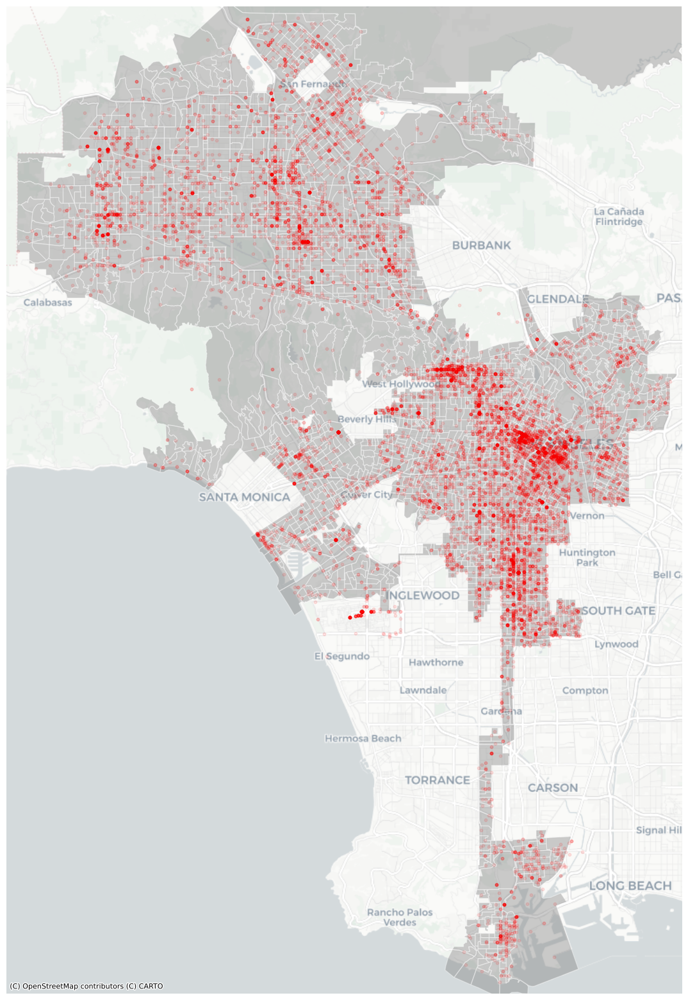

In [28]:
# set up the plot canvas with plt.subplots
fig, ax = plt.subplots(figsize=(20, 20))

# block groups
gdf_bg.plot(ax=ax, # this puts it in the ax plot
        color='gray', 
        edgecolor='white',
        alpha=0.4)

# arrests
arrests.plot(ax=ax, # this also puts it in the same ax plot
        color='red',
        markersize=10,
        alpha=0.1)

# use the bounding box coordinates to set the x and y limits
ax.set_xlim(minx - 1000, maxx + 1000) # added/substracted value is to give some margin around total bounds
ax.set_ylim(miny - 1000, maxy + 1000)

# no axis
ax.axis('off')

# add a basemap
ctx.add_basemap(ax,source=ctx.providers.CartoDB.Positron)

### Spatial Join

In [29]:
# check number of records before join
arrests.shape

(14277, 26)

In [30]:
# Do the spatial join
join = gpd.sjoin(gdf_bg, arrests, how='left')

In [31]:
# check number of records after join
join.shape

(14522, 29)

In [32]:
arrests_by_bg = join.FIPS.value_counts().rename_axis('FIPS').reset_index(name='arrests_count')
arrests_by_bg

,FIPS,arrests_count
0,060372088011,298
1,060372077111,236
2,060371282101,230
3,060372074001,151
4,060372396022,88
...,...,...
2666,060371011222,1
2667,060371011221,1
2668,060379800171,1
2669,060371012201,1


<Axes: xlabel='FIPS'>

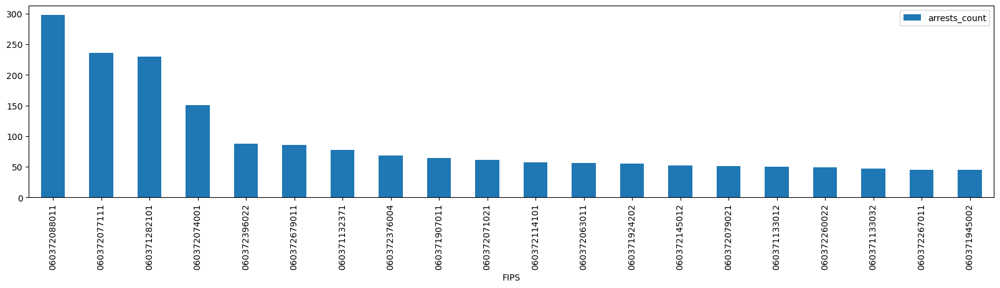

In [33]:
# make a bar chart of top 20 geographies
arrests_by_bg[:20].plot.bar(figsize=(20,4),
                             x='FIPS',
                             y='arrests_count')

### Join the value counts back to the geodata frame

In [34]:
# join the summary table back to the gdf
gdf_bg=gdf_bg.merge(arrests_by_bg,on='FIPS')

In [35]:
arrests_by_bg['arrests_count'].describe()

count    2671.000000
mean        5.436915
std        11.436605
min         1.000000
25%         1.000000
50%         3.000000
75%         6.000000
max       298.000000
Name: arrests_count, dtype: float64

In [36]:
# our block group table now has a count column
gdf_bg.sample(10)

,FIPS,TotalPop,geometry,arrests_count
2345,060372699051,940.0,"MULTIPOLYGON (((-13180739.112 4031930.136, -13...",1
1487,060372095101,872.0,"MULTIPOLYGON (((-13167123.625 4035820.353, -13...",8
1002,060371838202,1679.0,"MULTIPOLYGON (((-13157656.681 4042796.356, -13...",5
405,060371210104,1890.0,"MULTIPOLYGON (((-13181391.555 4059490.006, -13...",4
2173,060372426002,1915.0,"MULTIPOLYGON (((-13164003.117 4019536.209, -13...",11
959,060371814003,1941.0,"MULTIPOLYGON (((-13160075.209 4047615.729, -13...",6
2291,060372674041,1034.0,"MULTIPOLYGON (((-13187218.685 4034832.459, -13...",4
624,060371284003,1458.0,"MULTIPOLYGON (((-13186622.235 4053064.324, -13...",1
534,060371251021,1412.0,"MULTIPOLYGON (((-13179837.869 4050961.043, -13...",1
1869,060372294101,2365.0,"MULTIPOLYGON (((-13166195.665 4028161.147, -13...",9


### Normalizing: Arrests per 1000 people

In [37]:
gdf_bg['arrests_per_1000'] = gdf_bg['arrests_count']/gdf_bg['TotalPop']*1000

In [38]:
gdf_bg.sort_values(by="arrests_per_1000").tail()

,FIPS,TotalPop,geometry,arrests_count,arrests_per_1000
2028,060372376004,711.0,"MULTIPOLYGON (((-13167410.829 4025590.204, -13...",68,95.639944
1397,060372060511,406.0,"MULTIPOLYGON (((-13162384.42 4030801.699, -131...",42,103.448276
1429,060372077111,1881.0,"MULTIPOLYGON (((-13166062.193 4034545.23, -131...",236,125.465178
1461,060372088011,2301.0,"MULTIPOLYGON (((-13166927.035 4036610.273, -13...",298,129.508909
2665,060379800081,150.0,"MULTIPOLYGON (((-13191656.548 4058543.673, -13...",34,226.666667


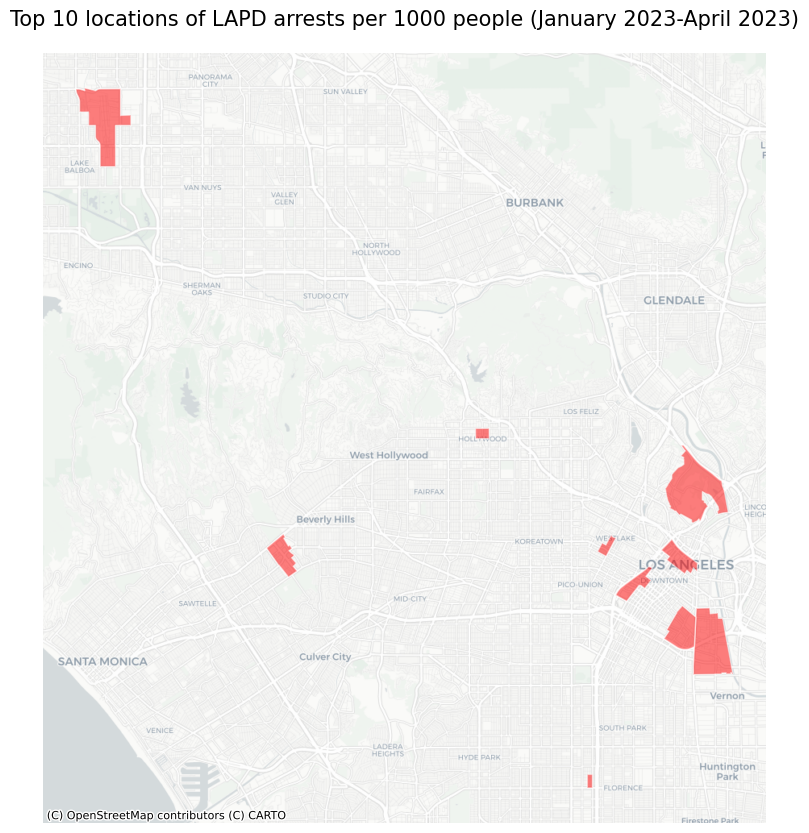

In [39]:
# map the top 20 geographies
fig,ax = plt.subplots(figsize=(12,10))
gdf_bg.sort_values(by='arrests_per_1000',ascending=False)[:10].plot(ax=ax,
                                                                 color='red',
                                                                 edgecolor='white',
                                                                 alpha=0.5)


# title
ax.set_title('Top 10 locations of LAPD arrests per 1000 people (January 2023-April 2023)',fontsize=15,pad=20)

# no axis
ax.axis('off')

# add a basemap
ctx.add_basemap(ax,source=ctx.providers.CartoDB.Positron)

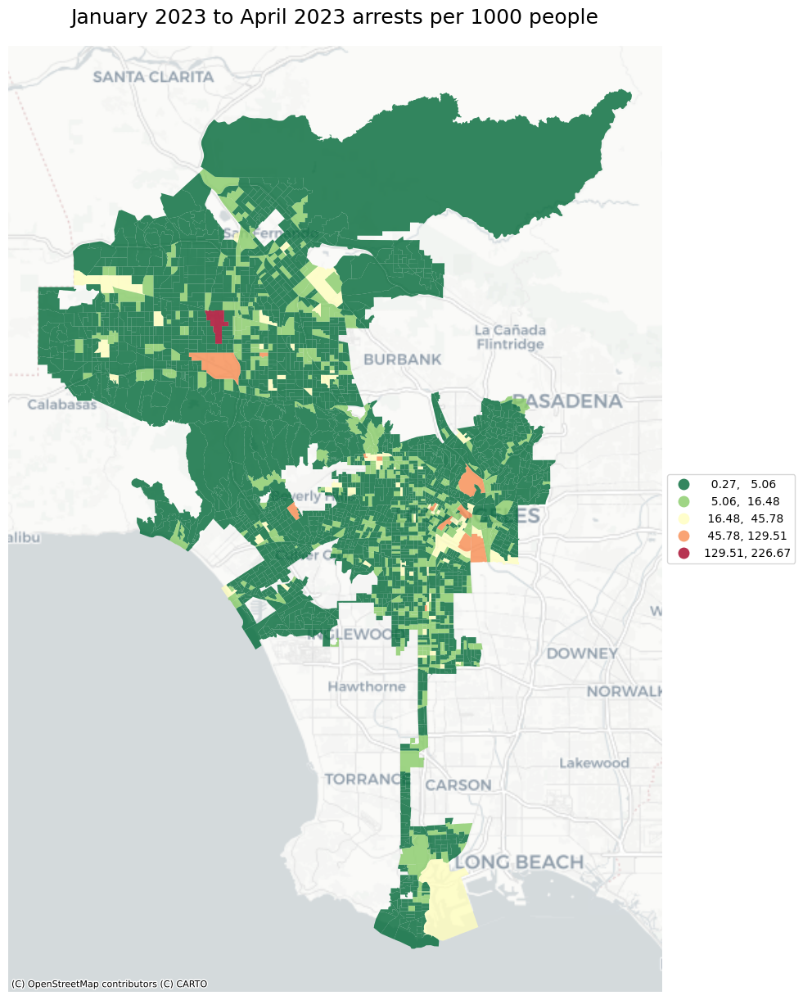

In [41]:
# create subplot to recieve chloropleth map
fig,ax = plt.subplots(figsize=(15,15))

gdf_bg.plot(ax=ax,
        column='arrests_per_1000', # this defines the field to "choropleth"
        legend=True,
        alpha=0.8,
        cmap='RdYlGn_r', # the "_r" reverses the color
        scheme='naturalbreaks',
           legend_kwds={'loc':'center left','bbox_to_anchor':(1,0.5)}) # code to move legend off to the side

ax.axis('off')
ax.set_title('January 2023 to April 2023 arrests per 1000 people',fontsize=18,pad=20)
ctx.add_basemap(ax,source=ctx.providers.CartoDB.Positron)

In [42]:
# a quick interactive version: geopandas .explore function does it all, no need to import folium!
gdf_bg.explore(column='arrests_per_1000', # this defines the field to "choropleth"
        legend=True,
        cmap='RdYlGn_r', # the "_r" reverses the color
        scheme='naturalbreaks',
        tiles='CartoDB positron',
        style_kwds={
            'weight':0.5,
            'color':'black',
            'opacity':0.5
        })

### Global Spatial Autocorrelation

In [44]:
# calculate spatial weight
wq =  lps.weights.KNN.from_dataframe(gdf_bg,k=8)

# Row-standardization
wq.transform = 'r'

In [45]:
# create a new column for the spatial lag
gdf_bg['arrests_per_1000_lag'] = lps.weights.lag_spatial(wq, gdf_bg['arrests_per_1000'])

In [46]:
# take a look at some sample rows
gdf_bg.sample(10)[['FIPS','TotalPop','arrests_count','arrests_per_1000','arrests_per_1000_lag']]

,FIPS,TotalPop,arrests_count,arrests_per_1000,arrests_per_1000_lag
1570,060372126102,2237.0,1,0.447027,4.030011
1482,060372094012,1819.0,5,2.748763,6.710305
674,060371317022,1506.0,3,1.992032,1.296254
2083,060372396011,2133.0,26,12.189405,10.007814
1841,060372283201,1025.0,2,1.951220,3.984425
86,060371047043,1357.0,3,2.210759,3.808637
2334,060372696013,842.0,7,8.313539,2.849537
2222,060372628022,614.0,3,4.885993,1.818776
2060,060372384001,895.0,4,4.469274,5.804191
959,060371814003,1941.0,6,3.091190,1.121504


In [47]:
# create a column that calculates the difference between arrests and lag
gdf_bg['arrest_lag_diff'] = gdf_bg['arrests_per_1000'] - gdf_bg['arrests_per_1000_lag']

In [48]:
# output to get the head and tail
gdf_bg.sort_values(by='arrest_lag_diff')

,FIPS,TotalPop,geometry,arrests_count,arrests_per_1000,arrests_per_1000_lag,arrest_lag_diff
577,060371274002,1557.0,"MULTIPOLYGON (((-13189788.05 4056808.73, -1318...",2,1.284522,32.388770,-31.104248
576,060371274001,1351.0,"MULTIPOLYGON (((-13189542.814 4058559.828, -13...",4,2.960770,33.937264,-30.976495
692,060371321022,1378.0,"MULTIPOLYGON (((-13191485.673 4056822.326, -13...",6,4.354136,30.320748,-25.966612
691,060371321021,231.0,"MULTIPOLYGON (((-13191486.229 4057459.033, -13...",1,4.329004,30.147127,-25.818123
1128,060371907021,585.0,"MULTIPOLYGON (((-13173399.15 4041965.005, -131...",3,5.128205,27.979364,-22.851159
...,...,...,...,...,...,...,...
1397,060372060511,406.0,"MULTIPOLYGON (((-13162384.42 4030801.699, -131...",42,103.448276,16.910055,86.538221
2028,060372376004,711.0,"MULTIPOLYGON (((-13167410.829 4025590.204, -13...",68,95.639944,8.394409,87.245535
1461,060372088011,2301.0,"MULTIPOLYGON (((-13166927.035 4036610.273, -13...",298,129.508909,14.102631,115.406278
1429,060372077111,1881.0,"MULTIPOLYGON (((-13166062.193 4034545.23, -131...",236,125.465178,4.850263,120.614915


In [49]:
# the FIPS with highest negative difference
gdf_donut = gdf_bg.sort_values(by='arrest_lag_diff').head(1)
gdf_donut

,FIPS,TotalPop,geometry,arrests_count,arrests_per_1000,arrests_per_1000_lag,arrest_lag_diff
577,060371274002,1557.0,"MULTIPOLYGON (((-13189788.05 4056808.73, -1318...",2,1.284522,32.38877,-31.104248


In [50]:
# the FIPS with highest positive difference
gdf_diamond = gdf_bg.sort_values(by='arrest_lag_diff').tail(1)
gdf_diamond

,FIPS,TotalPop,geometry,arrests_count,arrests_per_1000,arrests_per_1000_lag,arrest_lag_diff
2665,060379800081,150.0,"MULTIPOLYGON (((-13191656.548 4058543.673, -13...",34,226.666667,2.72355,223.943117


In [51]:
# map the donut
gdf_donut.explore(tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
                  attr='Tiles &copy; Esri &mdash; Source: Esri, i-cubed, USDA, USGS, AEX, GeoEye, Getmapping, Aerogrid, IGN, IGP, UPR-EGP, and the GIS User Community')

In [52]:
# map the diamond
gdf_diamond.explore(tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
                  attr='Tiles &copy; Esri &mdash; Source: Esri, i-cubed, USDA, USGS, AEX, GeoEye, Getmapping, Aerogrid, IGN, IGP, UPR-EGP, and the GIS User Community')

### Spatial Lag Map

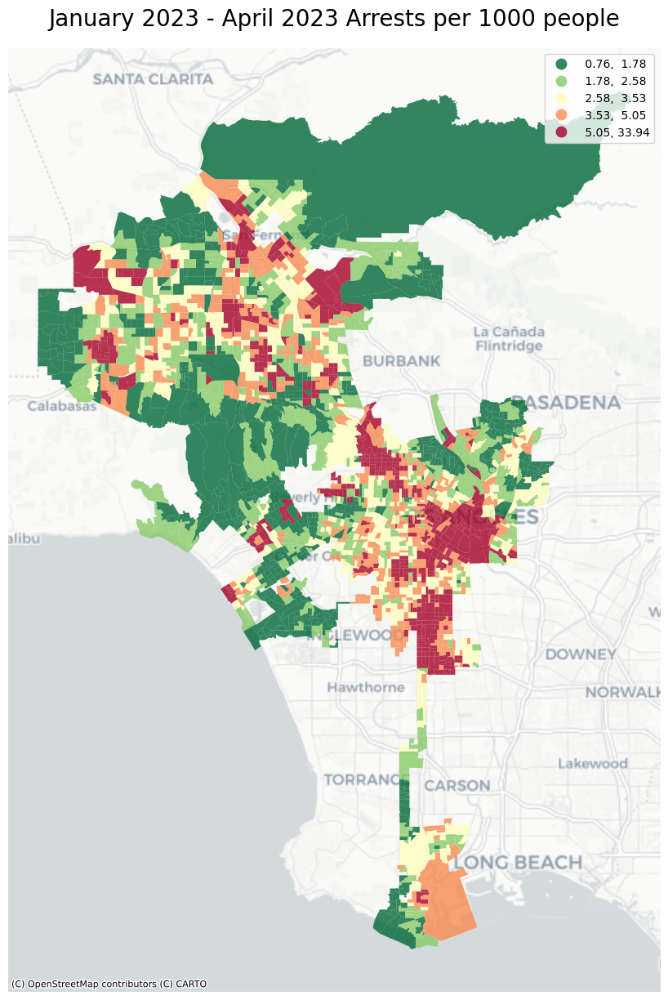

In [54]:
# use subplots that make it easier to create multiple layered maps
fig, ax = plt.subplots(figsize=(15, 15))

# spatial lag choropleth
gdf_bg.plot(ax=ax,
         figsize=(15,15),
         column='arrests_per_1000_lag',
         legend=True,
         alpha=0.8,
         cmap='RdYlGn_r',
         scheme='quantiles')

ax.axis('off')
ax.set_title('January 2023 - April 2023 Arrests per 1000 people',fontsize=20,pad=20)

ctx.add_basemap(ax,source=ctx.providers.CartoDB.Positron)

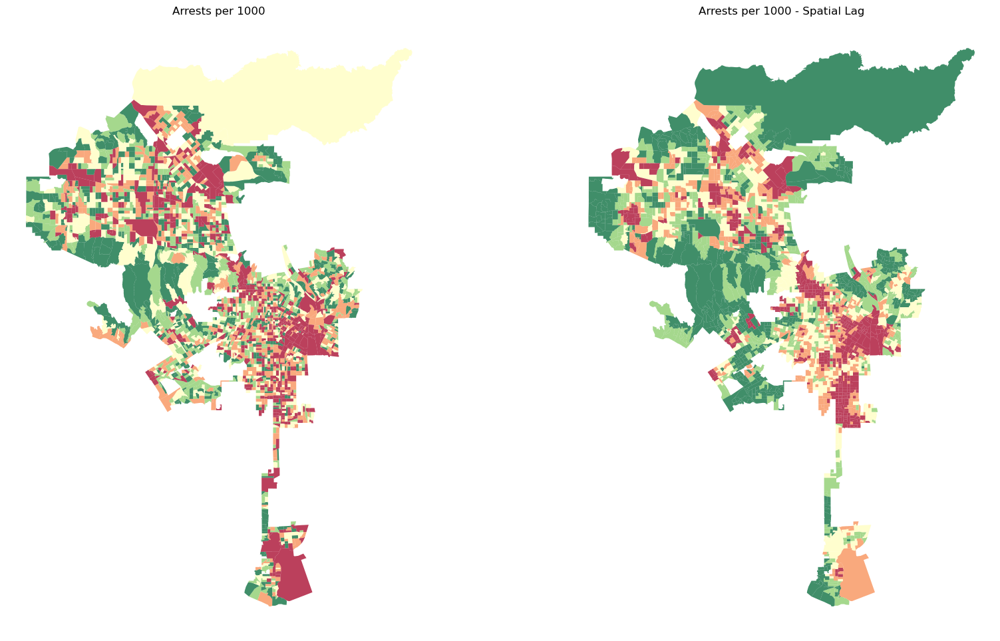

In [55]:
# create the 1x2 subplots
fig, ax = plt.subplots(1, 2, figsize=(20, 12))

# two subplots produces ax[0] (left) and ax[1] (right)

# regular count map on the left
gdf_bg.plot(ax=ax[0], # this assigns the map to the left subplot
         column='arrests_per_1000', 
         cmap='RdYlGn_r', 
         scheme='quantiles',
         k=5, 
         edgecolor='white', 
         linewidth=0, 
         alpha=0.75, 
           )


ax[0].axis("off")
ax[0].set_title("Arrests per 1000")

# spatial lag map on the right
gdf_bg.plot(ax=ax[1], # this assigns the map to the right subplot
         column='arrests_per_1000_lag', 
         cmap='RdYlGn_r', 
         scheme='quantiles',
         k=5, 
         edgecolor='white', 
         linewidth=0, 
         alpha=0.75
           )

ax[1].axis("off")
ax[1].set_title("Arrests per 1000 - Spatial Lag")

plt.show()

# save the figure as a png file
fig.savefig('arrests_spatial_lag_comparison.png', dpi=300, bbox_inches='tight')

### Moran's Plot and Map

In [56]:
y = gdf_bg.arrests_per_1000
moran = Moran(y, wq)
moran.I

np.float64(0.10356354955933382)

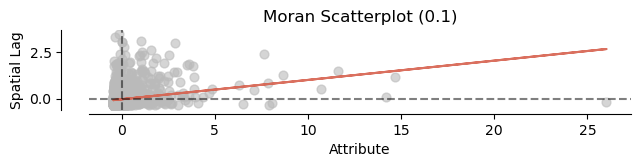

In [57]:
fig, ax = moran_scatterplot(moran, aspect_equal=True)
plt.show()

(<Figure size 700x700 with 1 Axes>,
 <Axes: title={'center': 'Reference Distribution'}, xlabel='Moran I: 0.1', ylabel='Density'>)

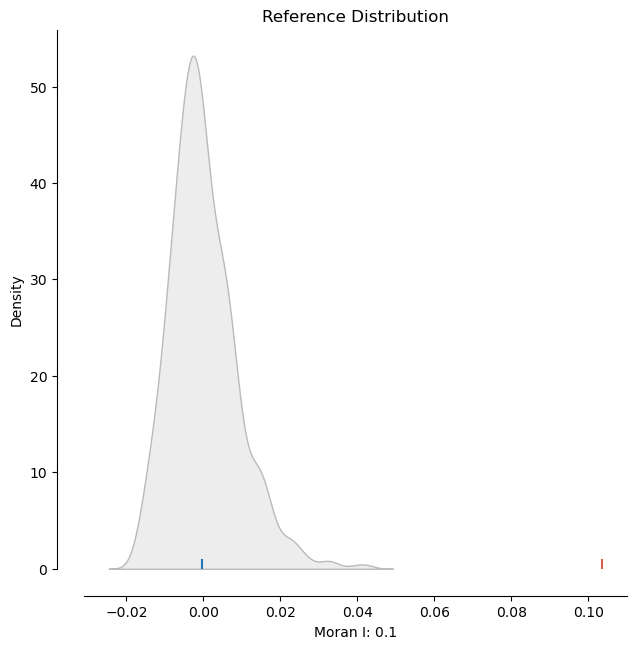

In [58]:
plot_moran_simulation(moran,aspect_equal=False)

In [59]:
moran.p_sim

np.float64(0.001)

In [60]:
# calculate local moran values
lisa = esda.moran.Moran_Local(y, wq)

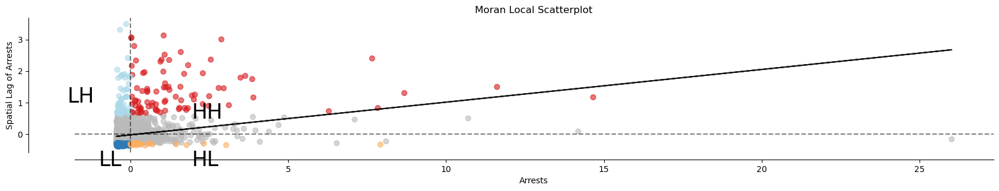

In [61]:
# Local Moran Scatterplot
# Plot
fig,ax = plt.subplots(figsize=(20,15))

moran_scatterplot(lisa, ax=ax, p=0.05)
ax.set_xlabel("Arrests")
ax.set_ylabel('Spatial Lag of Arrests')

# add some labels
plt.text(1.95, 0.5, "HH", fontsize=25)
plt.text(1.95, -1, "HL", fontsize=25)
plt.text(-2, 1, "LH", fontsize=25)
plt.text(-1, -1, "LL", fontsize=25)
plt.show()

### Spatial Autocorrelation Map

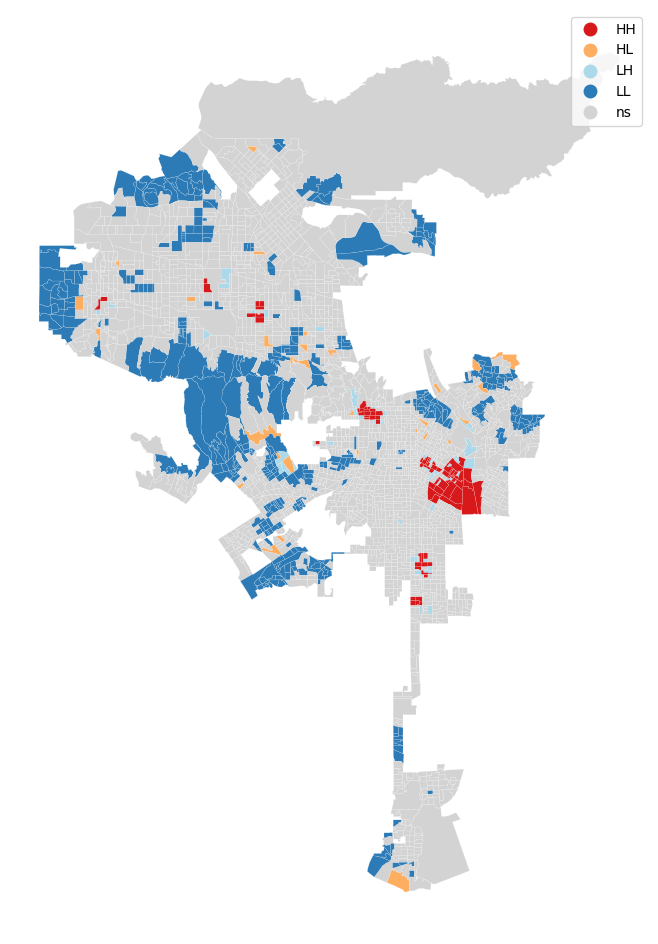

In [62]:
fig, ax = plt.subplots(figsize=(14,12))
lisa_cluster(lisa, gdf_bg, p=0.05, ax=ax)
plt.show()

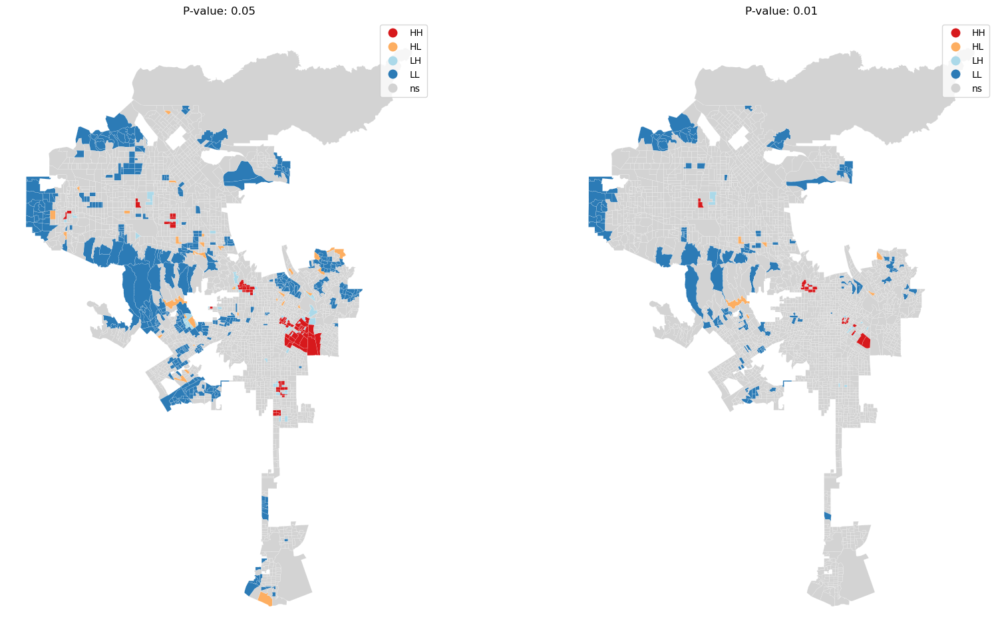

In [63]:
# create the 1x2 subplots
fig, ax = plt.subplots(1, 2, figsize=(20, 12))

# regular count map on the left
lisa_cluster(lisa, gdf_bg, p=0.05, ax=ax[0])

ax[0].axis("off")
ax[0].set_title("P-value: 0.05")

# spatial lag map on the right
lisa_cluster(lisa, gdf_bg, p=0.01, ax=ax[1])
ax[1].axis("off")
ax[1].set_title("P-value: 0.01")

plt.show()

The data shown in the maps made with spatial statistics highlight that the million dollar hoods that our group identified as the top places for arrests and extraction that our is working with is not the most accurate designation for where the most arrests are taking place, statistically. The implications that come from this map for the purposes of our final project show that we can't necessaily base our analysis on specific neighborhoods where million dollar hoods have been identitfied, but rather invite us to look more expansively at where else extraction takes place around Los Angeles and compare it to where arrests are taking place, to develop a wider undertanding.

For this assignment, Leila compiled the code, Hollis located the data, and Amil conducted the analysis.